<ipython-input-1-7fb3c0269673>:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('/home/xfang/projects/CVAE_SMS/SMS_models_kld/model_Extrac

torch.Size([1, 4, 3600])
torch.Size([7200, 4])


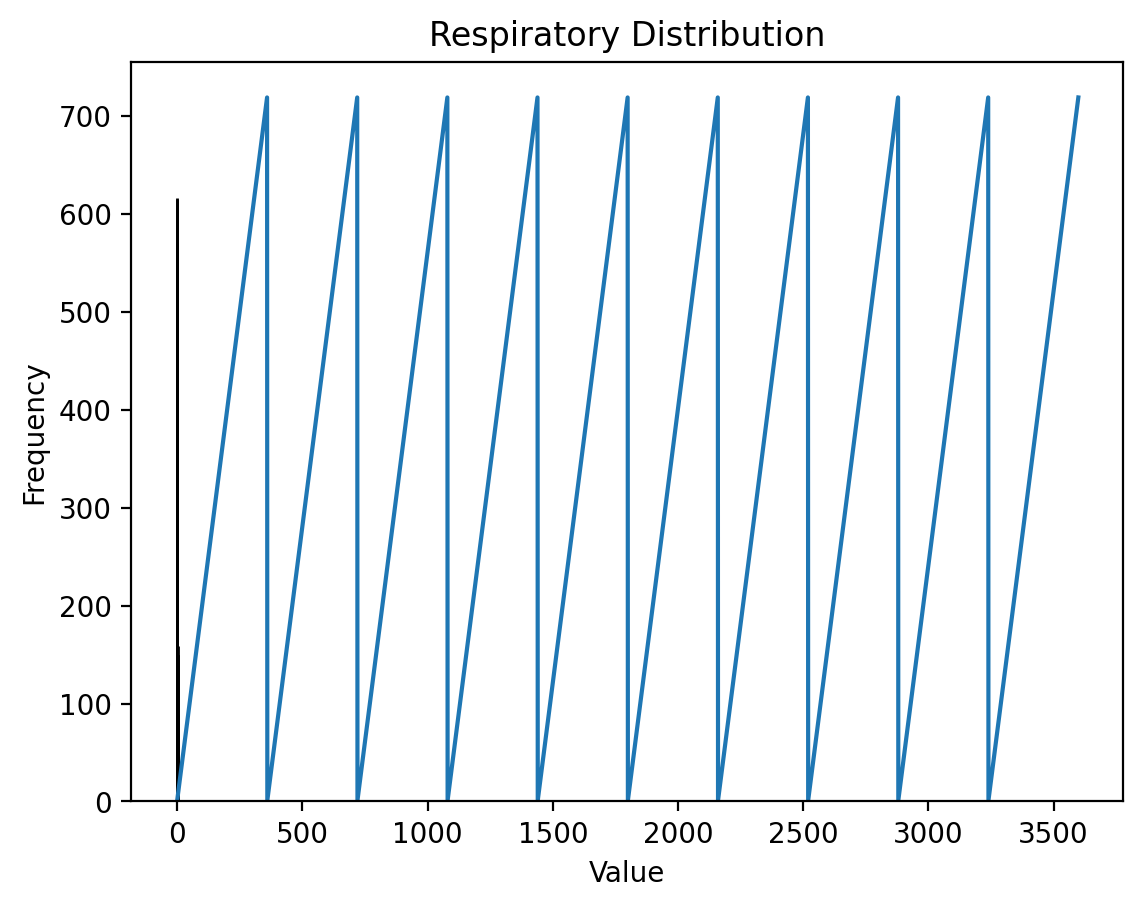

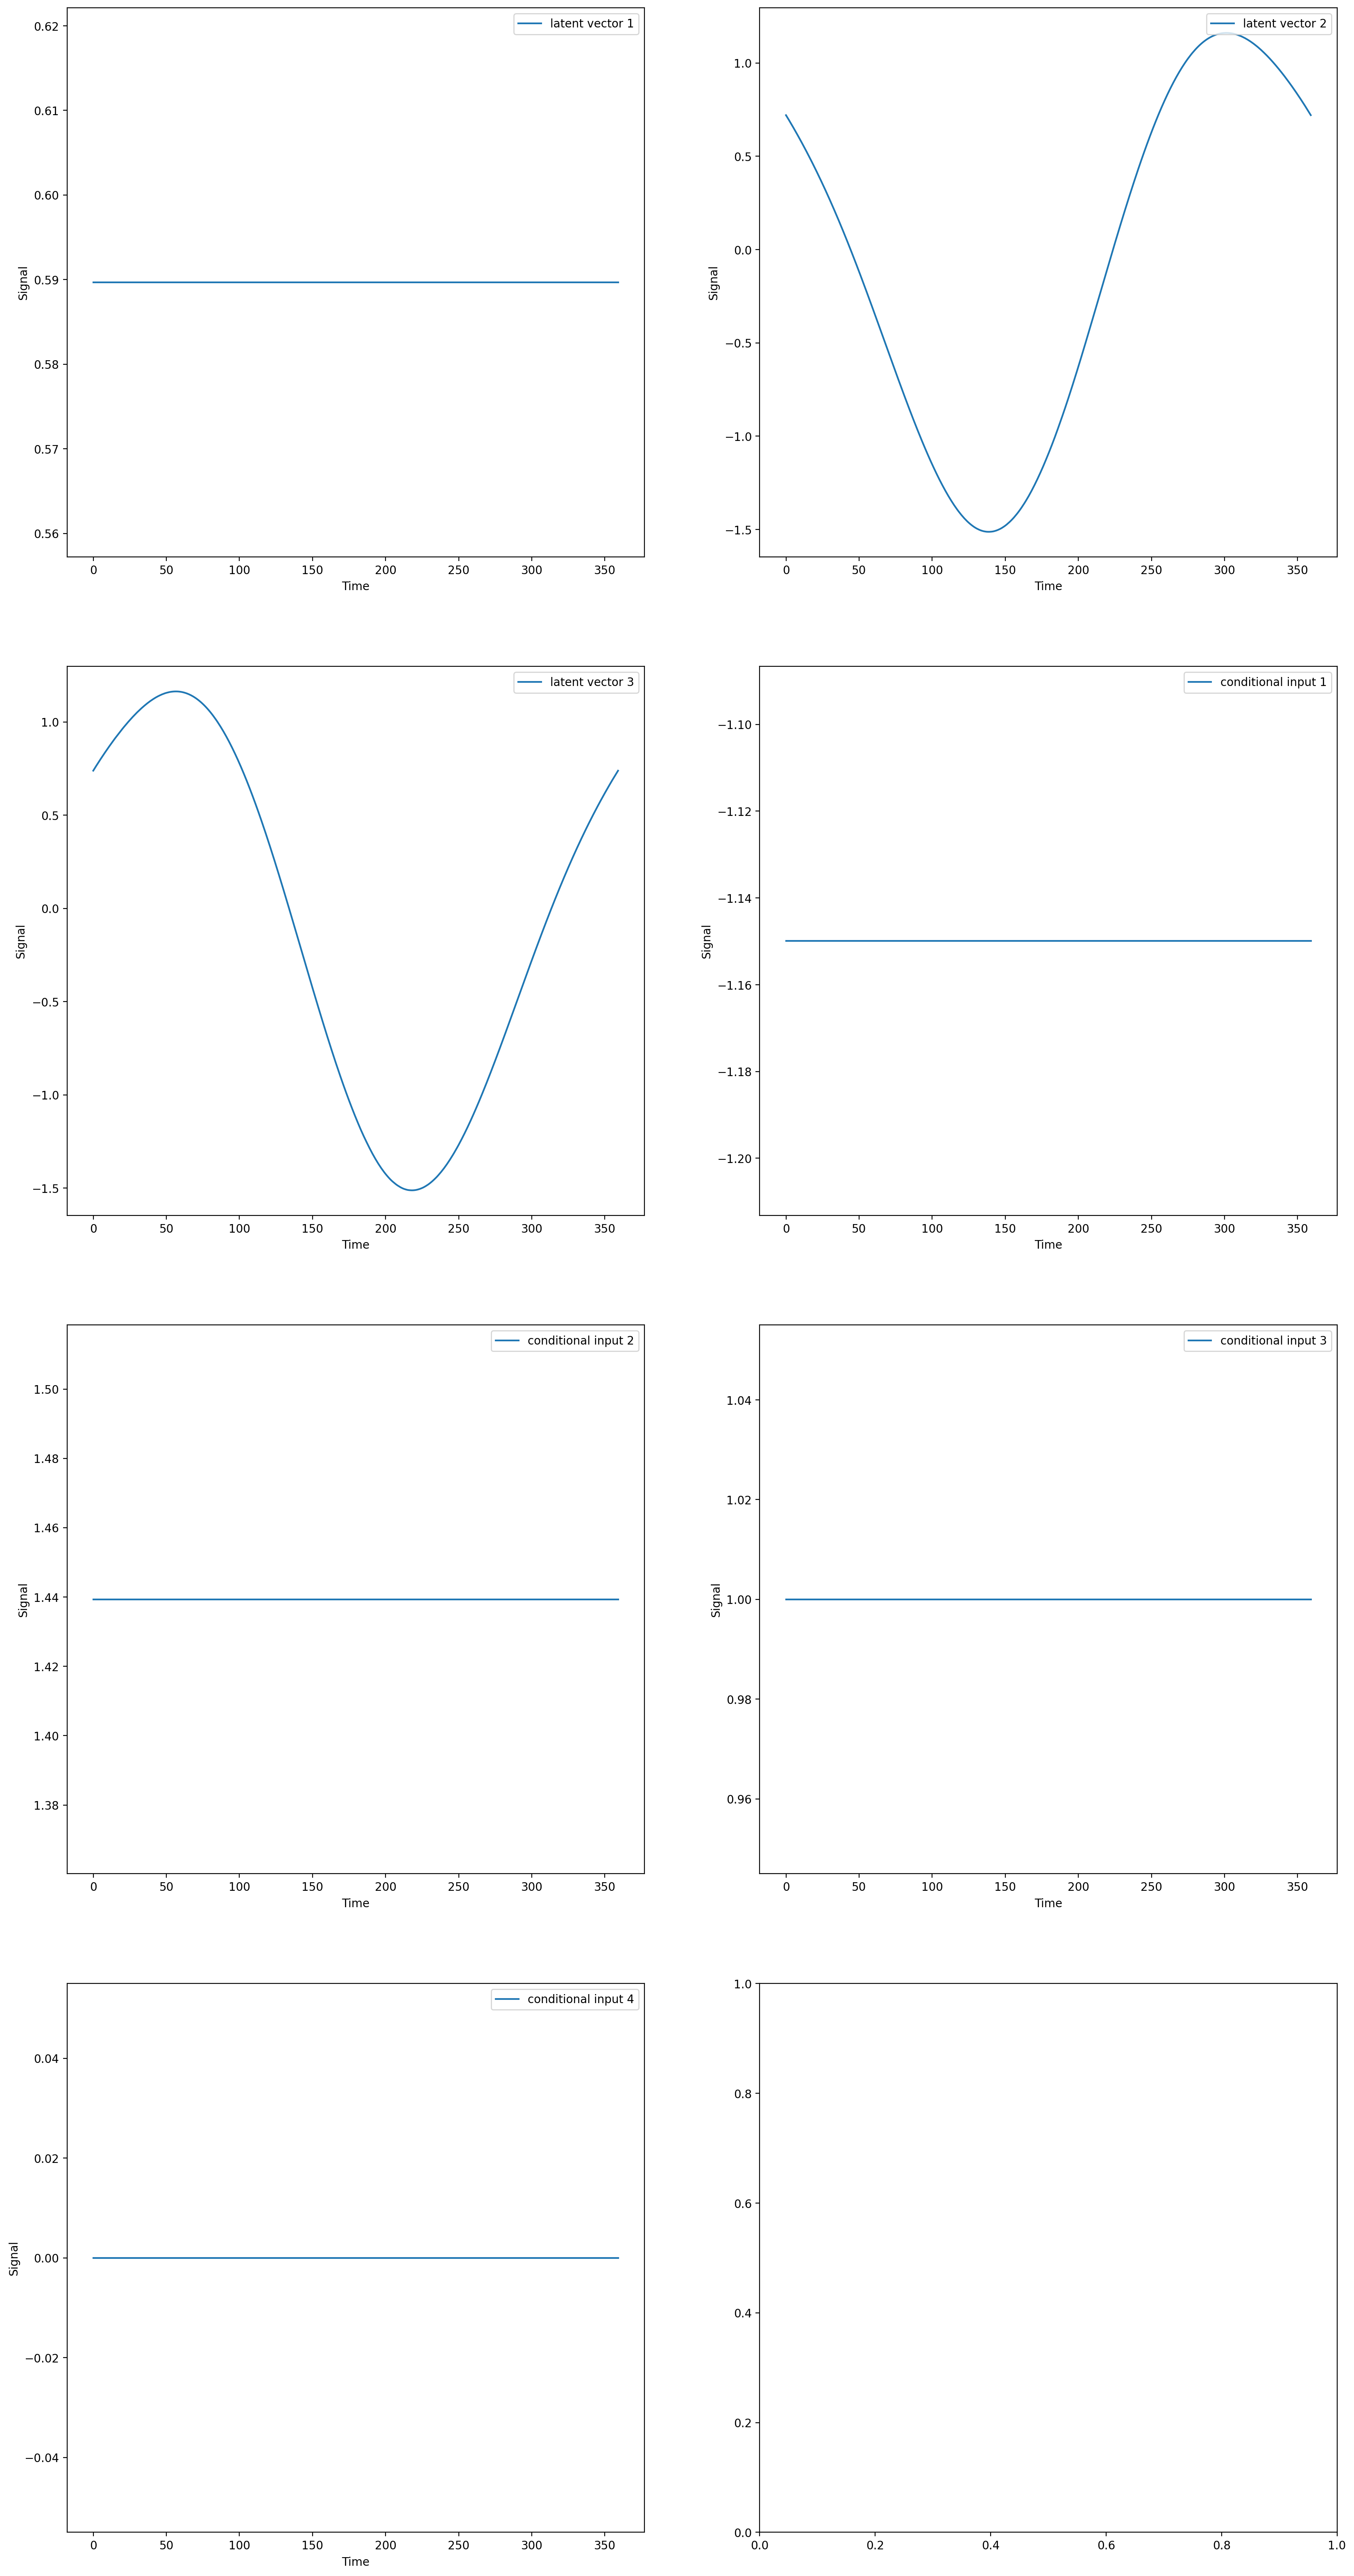

In [1]:
import os
import sys
import torch

torch.manual_seed(0)
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
import torch.utils
import torch.distributions
import torch.optim as optim
from tqdm import tqdm
from network import VAE, CVAE, CVAE_BP, CVAE_BP_HT
import torchvision
import mat73
import numpy as np
import scipy
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 200
from sklearn.feature_selection import mutual_info_regression
import scipy.stats as stats
import statsmodels.api as sm
from scipy.interpolate import interp1d
from scipy.interpolate import CubicSpline
from scipy.io import savemat

torch.autograd.set_detect_anomaly(True)

# Configuration
device = "cuda" if torch.cuda.is_available() else "cpu"
path = os.path.dirname(os.path.realpath(__file__))


# load data and conditional information
data_file = "/home/xfang/projects/CVAE_SMS/SMS_data/ExtractToPython_0604_run1.mat"
mat_data = mat73.loadmat(data_file)
mat_data = mat_data["ExtractToPython"]
Phi_rt_init = mat_data["Phi_rt_small"]
Segidx = mat_data["Segidx"].reshape(-1, 1)
wallClock = mat_data["wallClock"].reshape(-1, 1)
thetas = mat_data["thetas"].reshape(-1, 1)

plt.plot(Segidx[:3600])
plt.savefig('test.png')

if "flipAngle" in mat_data:
    flipAngles = mat_data["flipAngle"].reshape(-1, 1)
    IFdualFA = True
else:
    flipAngles = np.zeros_like(thetas)
    
### fixing wallclock ###
wallClock = (wallClock - 1) % 5 + 1

### processing mat data ###
Segidx_mu = (Segidx - Segidx.mean()) / Segidx.std()
wallClock_mu = (wallClock - wallClock.mean()) / wallClock.std()
thetas_mu = (thetas - thetas.mean()) / thetas.std()
flipAngles_mu = (flipAngles - flipAngles.mean()) / flipAngles.std()

wallClock_mu = torch.from_numpy(wallClock_mu).to(device)
Segidx_mu = torch.from_numpy(Segidx_mu).to(device)
thetas_mu = torch.from_numpy(thetas_mu).to(device).to(torch.float32)
flipAngles_mu = torch.from_numpy(flipAngles_mu).to(device)
theta0 = torch.zeros_like(thetas_mu).to(torch.float32)

### resample data for mapping

### Concatenating the data for conditional input ###
t1t2_normalized = torch.cat([Segidx_mu, wallClock_mu], dim=1).to(torch.float32)
t1t2theta = torch.cat([Segidx_mu, wallClock_mu, thetas_mu], dim=1).to(torch.float32)
t1t2theta0 = torch.cat([Segidx_mu, wallClock_mu, theta0], dim=1).to(torch.float32)
t1t2fatheta = torch.cat(
    [Segidx_mu, wallClock_mu, flipAngles_mu, thetas_mu], dim=1
).to(torch.float32)
t1t2fatheta0 = torch.cat(
    [Segidx_mu, wallClock_mu, flipAngles_mu, theta0], dim=1
).to(torch.float32)

# conditional input for cardiac movements
fixedT1_value_card = Segidx_mu[1500,:]
fixedT2_value_card = wallClock_mu[1500,:]
fixedT1_card = torch.ones_like(Segidx_mu).to(device) * fixedT1_value_card
fixedT2_card = torch.ones_like(wallClock_mu).to(device) * fixedT2_value_card
fixedcontrast_card = torch.cat([fixedT1_card, fixedT2_card], dim=1).to(torch.float32)
smallFA = torch.ones_like(flipAngles_mu).to(device) * min(flipAngles_mu)
bigFA = torch.ones_like(flipAngles_mu).to(device) * max(flipAngles_mu)
cardfixedcontrastsmallFAtheta0 = torch.cat([fixedcontrast_card, smallFA, theta0], dim=1).to(torch.float32)
cardfixedcontrastbigFAtheta0 = torch.cat([fixedcontrast_card, bigFA, theta0], dim=1).to(torch.float32)

# conditional input for respiratory movements 
fixedT1_value_resp = Segidx_mu[1585,:]
fixedT2_value_resp = wallClock_mu[1585,:]
fixedT1_resp = torch.ones_like(Segidx_mu).to(device) * fixedT1_value_card
fixedT2_resp = torch.ones_like(wallClock_mu).to(device) * fixedT2_value_card
fixedcontrast_resp = torch.cat([fixedT1_resp, fixedT2_resp], dim=1).to(torch.float32)
smallFA = torch.ones_like(flipAngles_mu).to(device) * min(flipAngles_mu)
bigFA = torch.ones_like(flipAngles_mu).to(device) * max(flipAngles_mu)
respfixedcontrastsmallFAtheta0 = torch.cat([fixedcontrast_resp, smallFA, theta0], dim=1).to(torch.float32)
respfixedcontrastbigFAtheta0 = torch.cat([fixedcontrast_resp, bigFA, theta0], dim=1).to(torch.float32)

Phi_rt_init = Phi_rt_init / Phi_rt_init[:, 0].std()  # Normalize whole
# Phi_rt_init = (Phi_rt_init - Phi_rt_init.mean(axis=1, keepdims=True)) / Phi_rt_init.std(axis=1, keepdims=True) #Normalize each feature
Phi_rt_init_real = Phi_rt_init.real
Phi_rt_init_imag = Phi_rt_init.imag
Phi_rt_init_con = np.concatenate((Phi_rt_init_real, Phi_rt_init_imag))
Phi_rt_init_con = Phi_rt_init_con.transpose()
Phi_rt_init = torch.from_numpy(Phi_rt_init_con).float().to(device)

feature_size = Phi_rt_init.size()[1]
model = CVAE_BP_HT(feature_size, latent_dims=2, class_size=4).to(device)
model.load_state_dict(torch.load('/home/xfang/projects/CVAE_SMS/SMS_models_kld/model_ExtractToPython_0604_run1.pth'))

recon_output_ec, latent_space_mu, latent_space_logvar = model(Phi_rt_init, t1t2fatheta)
recon_output_ec = model.decode(latent_space_mu, t1t2fatheta).to("cpu").detach().numpy()
recon_output = model.decode(latent_space_mu, t1t2fatheta0).to("cpu").detach().numpy()
latent_space = model.reparameterize(latent_space_mu, latent_space_logvar)
latent_space = latent_space.to("cpu").detach().numpy()
latent_space_mu = latent_space_mu.to("cpu").detach().numpy()

resp = latent_space_mu[:, 0]
resp_min = np.percentile(resp, 10)
resp_max = np.percentile(resp, 90)
counts, bins, patches = plt.hist(resp, bins=100, edgecolor="black")
resp0_index = np.argmax(counts)
bin_range = (bins[resp0_index], bins[resp0_index + 1])
resp0 = (bin_range[0] + bin_range[1]) / 2
resp_phase = 20
plt.title("Respiratory Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.savefig("./SMS_output/resp_distribution.png")

# cardiac cycle

cardiac1 = latent_space_mu[:, 1]
np.save("./SMS_output/ExtractToPython_0601_run1_cardiac1.npy", cardiac1)
cardiac2 = latent_space_mu[:, 2]
np.save("./SMS_output/ExtractToPython_0601_run1_cardiac2.npy", cardiac2)

def average_cycle(cardiac1, cardiac2):
    card_amplitude = np.sqrt(cardiac1**2 + cardiac2**2)
    card_phase = np.arctan2(cardiac2, cardiac1)
    left_phase = card_phase - 2*np.pi
    right_phase = card_phase + 2*np.pi
    padded_amplitude = np.concatenate((card_amplitude, card_amplitude, card_amplitude))
    padded_phase = np.concatenate((left_phase, card_phase, right_phase))
    lowess = sm.nonparametric.lowess
    smoothed_cardiac = lowess(padded_amplitude, padded_phase, frac=0.3)
    smoothed_phase = smoothed_cardiac[:, 0]
    smoothed_amplitude = smoothed_cardiac[:, 1]
    min_index = np.argmin(smoothed_amplitude)  # Index of min amplitude
    min_phase = smoothed_phase[min_index]  # Corresponding phase
    phase0 = min_phase
    unique_phase, unique_indices = np.unique(smoothed_phase, return_index=True)
    unique_amplitude = smoothed_amplitude[unique_indices]  # Keep only unique amplitude
    amplitude_function = interp1d(unique_phase, unique_amplitude, kind="cubic", fill_value="extrapolate")
    return phase0, amplitude_function

phase0, amplitude_function = average_cycle(cardiac1, cardiac2)



# plt.figure(figsize=(8, 6))
# plt.scatter(smoothed_data[:,0], smoothed_data[:,1], s=1, alpha=0.7, color='b')
# plt.xlabel("Phase (degrees)")
# plt.ylabel("Cardiac Amplitude")
# plt.title("Scatter Plot of Cardiac Amplitude vs. Phase")
# plt.grid(True)
# plt.savefig("cardiac_scatter.png")



# phase_diff = np.diff(card_phase)
# threshold = -np.pi
# drop = np.where(phase_diff < threshold)[0]

# print(drop)

# fig, ax1 = plt.subplots(figsize=(10, 5))

# # Plot Phase
# ax1.plot(card_phase[:1000], label="Cardiac Phase", color="tab:blue")
# ax1.set_xlabel("Time (s)")
# ax1.set_ylabel("Phase (radians)", color="tab:blue")
# ax1.tick_params(axis='y', labelcolor="tab:blue")

# # Create second y-axis for Amplitude
# ax2 = ax1.twinx()
# ax2.plot(card_amplitude[:1000], label="Cardiac Amplitude", color="tab:red", linestyle="dashed")
# ax2.set_ylabel("Amplitude", color="tab:red")
# ax2.tick_params(axis='y', labelcolor="tab:red")

# # Title and Grid
# plt.title("Cardiac Phase and Amplitude Over Time")
# ax1.grid()

# fig.savefig('test1.png')
   

# cardiac
numcard = 360
aver_card_phase = np.linspace(phase0, phase0+2*np.pi, numcard)
aver_card_phase = (aver_card_phase + np.pi) % (2 * np.pi) - np.pi
aver_card_amplitude = amplitude_function(aver_card_phase)
latent_space_mu_card = torch.ones(numcard, 3).to(device)
latent_space_mu_card[:, 0] = resp0 * latent_space_mu_card[:, 0]
latent_space_mu_card[:, 1] = torch.from_numpy(aver_card_amplitude * np.cos(aver_card_phase))
latent_space_mu_card[:, 2] = torch.from_numpy(aver_card_amplitude * np.sin(aver_card_phase))
recon_output_card = (
    model.decode(latent_space_mu_card, cardfixedcontrastbigFAtheta0[:numcard, :])
    .to("cpu")
    .detach()
    .numpy()
)  # NO REPARAMETERIZATION


fig1, axs1 = plt.subplots(4,2, figsize=(20, 40))
axs1= axs1.flatten()  # Flatten the 2x2 array of axes for easy indexing
for i in range(3):
    axs1[i].plot(latent_space_mu_card[:, i].to('cpu').detach().numpy(), label = f'latent vector {i+1}')
    axs1[i].legend(loc="upper right")
    axs1[i].set_xlabel("Time")
    axs1[i].set_ylabel("Signal")
for i in range(4):
    axs1[i+3].plot(cardfixedcontrastbigFAtheta0[:numcard, i].to('cpu').detach().numpy(), label = f'conditional input {i+1}')
    axs1[i+3].legend(loc="upper right")
    axs1[i+3].set_xlabel("Time")
    axs1[i+3].set_ylabel("Signal")
fig1.savefig("test2.png")


# resp
latent_space_mu_resp = torch.ones(resp_phase, 3).to(device)
latent_space_mu_resp[:, 1] = amplitude_function(phase0) * np.cos(phase0) * torch.ones(resp_phase)
latent_space_mu_resp[:, 2] = amplitude_function(phase0) * np.sin(phase0) * torch.ones(resp_phase)
latent_space_mu_resp[:, 0] = torch.linspace(resp_min, resp_max, resp_phase)
recon_output_resp = (
    model.decode(latent_space_mu_resp, respfixedcontrastsmallFAtheta0[:resp_phase, :])
    .to("cpu")
    .detach()
    .numpy()
)  # NO REPARAMETERIZATION

# contrast recovery
latent_space_mu_recovery = torch.ones(3600, 3).to(device)
latent_space_mu_recovery[:, 0] = resp0 * latent_space_mu_recovery[:, 0]
latent_space_mu_recovery[:, 1] = amplitude_function(phase0) * np.cos(phase0) * latent_space_mu_recovery[:, 1]
latent_space_mu_recovery[:, 2] = amplitude_function(phase0) * np.sin(phase0) * latent_space_mu_recovery[:, 2]
recon_recovery = (
    model.decode(latent_space_mu_recovery, t1t2fatheta0[:3600, :])
    .to("cpu")
    .detach()
    .numpy()
)


cbins = 20
rbins = 6
contrast_num = 3600
conditional_input = 4
conditional = t1t2fatheta0[:contrast_num,:].unsqueeze(0).permute(0, 2, 1)
print(conditional.shape)
conditional_up = F.interpolate(conditional, size=2*contrast_num, mode='linear', align_corners=True)
conditional_up = conditional_up.permute(0, 2, 1).squeeze(0)
print(conditional_up.shape)

latent_space_mu_fitting = torch.ones(contrast_num*2*cbins*rbins, 3).to(device)
resp_bins = torch.linspace(resp_min, resp_max, rbins)
latent_space_mu_fitting[:,0] = resp_bins.repeat_interleave(contrast_num*2*cbins)
card_phase_values = torch.linspace(phase0, phase0+2*np.pi, cbins)
card_phase_values = (card_phase_values + np.pi) % (2 * np.pi) - np.pi
card_phase_bins = card_phase_values.repeat_interleave(contrast_num*2).repeat(rbins)
card_amplitude_bins = amplitude_function(card_phase_bins)
latent_space_mu_fitting[:,1] = torch.from_numpy(card_amplitude_bins) * torch.cos(card_phase_bins)
latent_space_mu_fitting[:,2] = torch.from_numpy(card_amplitude_bins) * torch.sin(card_phase_bins)
condition_fitting = conditional_up.repeat(cbins*rbins,1)
phi4fitting = model.decode(latent_space_mu_fitting,condition_fitting).to("cpu").detach().numpy()



savemat(
    "/home/xfang/Data/Multitasking_SMS/Human_SMS_20210604/2D_SMS_DATA/0604_run1.mat",
    {
        "resp": recon_output_resp,
        "card": recon_output_card,
        "realtime": recon_output,
        "recovery": recon_recovery,
        "phi4fitting": phi4fitting,
    },
)

# # Plotting
# fig2, axs2 = plt.subplots(2, 4, figsize=(20, 20))
# axs2 = axs2.flatten()  # Flatten the 2x2 array of axes for easy indexing
# for i in range(4):
#     axs2[i].plot(Phi_rt_init[:3600, i].cpu(), label = f'Phi_rt_init Col {i+1}')
#     axs2[i].plot(recon_output[:3600, i], label = f'Recon_output w/eddy current Col {i+1}')
#     axs2[i].legend(loc="upper right")
# for i in range(4):
#     axs2[i+4].plot(Phi_rt_init[:3600, i].cpu(), label=f'Phi_rt_init Col {i+1}')
#     axs2[i+4].plot(recon_output[:3600, i], label=f'Recon_output Col {i+1}')
#     axs2[i+4].legend(loc="upper right")
# plt.tight_layout()
# fig2.savefig('recon_output.png')